In [ ]:
from pprint import pprint

import torch

# Dataset preparation
import torchvision.datasets as datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader

# Training
from torch import nn
from torch import optim

# Testing
from torchmetrics import Accuracy

# Helper functions
from tqdm import tqdm
import matplotlib.pyplot as plt

# For tensor operations
if torch.backends.mps.is_available:
    device = torch.device("mps")
    print(f"Successfully set device: {device}")
else:
    device = torch.device("cpu")
    print("MPS not available, using CPU.")

transforms = v2.Compose([
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True)
])

Successfully set device: mps


In [2]:
# MNIST images are 28x28 pixels
# Train contains 60,000 and test contains 10,000
# transform converts the PIL image to tensor of shape (1, 28, 28) - 1 channel for greyscale, and converts pixel values from 0-255 -> 0.0-1.0
train = datasets.MNIST(root="./dataset/", train=True, transform=transforms, download=True)
test = datasets.MNIST(root="./dataset/", train=False, transform=transforms, download=True)

TRAIN_BATCH_SIZE = 64
train_loader = DataLoader(train, batch_size=TRAIN_BATCH_SIZE, shuffle=True)

TEST_BATCH_SIZE = 64  # tuned to fit device memory
test_loader = DataLoader(test, batch_size=TEST_BATCH_SIZE, shuffle=True)

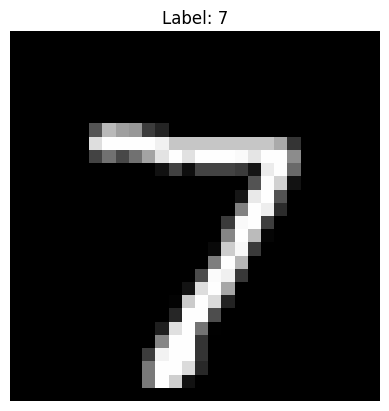

In [3]:
# Display a sample image
img = test.data[0].numpy()
label = int(test.targets[0]) if hasattr(test, 'targets') else None
plt.imshow(img, cmap='gray')
plt.title(f'Label: {label}')
plt.axis('off')
plt.show()

In [4]:
class CNN(nn.Module):
    def __init__(self, num_inputs=1, num_labels=10):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=num_inputs, out_channels=8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )
        
        self.classifier = nn.Sequential(
            # Flatten tensor from shape 16,28,28 to 1D tensor (16*28*28)
            nn.Flatten(),
            # Linear layer that contains 10 nodes
            nn.Linear(in_features=16*28*28, out_features=num_labels)
        )
    
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [5]:
model = CNN().to(device=device)
pprint(model)

LEARNING_RATE = 0.001
NUM_EPOCHS = 10

# Use cross entropy loss function
criterion = nn.CrossEntropyLoss()
# AdamW as optimizer
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)


for e in range(NUM_EPOCHS):
    pprint(f"Running Epoch {e+1}")
    
    for batch, (inputs, targets) in enumerate(tqdm(train_loader)):
        inputs = inputs.to(device)
        targets = targets.to(device)
        scores = model(inputs)
        loss = criterion(scores, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

CNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12544, out_features=10, bias=True)
  )
)
'Running Epoch 1'


100%|██████████| 938/938 [00:05<00:00, 159.10it/s]


'Running Epoch 2'


100%|██████████| 938/938 [00:05<00:00, 174.38it/s]


'Running Epoch 3'


...

100%|██████████| 938/938 [00:05<00:00, 171.74it/s]


'Running Epoch 9'


100%|██████████| 938/938 [00:05<00:00, 172.06it/s]


'Running Epoch 10'


100%|██████████| 938/938 [00:05<00:00, 173.00it/s]


In [6]:
import torch

# Save only the model weights (state_dict)
torch.save(model.state_dict(), "mnist_model_weights.pth")


# # Load the model
# model.load_state_dict(torch.load("mnist_model_weights.pth"))

In [ ]:
# Predict 1 of the 10 digits
acc = Accuracy(task="multiclass", num_classes=10).to(device)

# Iterate over the dataset batches
model.eval()

with torch.no_grad():
    for test_inputs, test_labels in test_loader:
        test_inputs = test_inputs.to(device)
        test_labels = test_labels.to(device)
        
        outputs = model(test_inputs)
        _, preds = torch.max(outputs, 1)
        acc(preds, test_labels)

test_accuracy = acc.compute()
print(f"Test accuracy: {test_accuracy}")

Test accuracy: 0.9832000136375427
